<a href="https://colab.research.google.com/github/mrxein/research-gate/blob/main/DDPM_FashionMNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available.")


PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
Selected device: cuda
GPU: Tesla T4


In [2]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)


Random seed set to: 42


In [3]:

import torch
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader
from torchvision.datasets import FashionMNIST

# Dataset transformation
transform = transforms.ToTensor()

# Download training dataset
train_dataset = FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download test dataset
test_dataset = FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))


100%|██████████| 26.4M/26.4M [00:02<00:00, 10.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 175kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.23MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.8MB/s]

Training samples: 60000
Testing samples: 10000


In [4]:
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image minimum:", images.min().item())
print("Image maximum:", images.max().item())


Image batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])
Image minimum: 0.0
Image maximum: 1.0


In [5]:

class_names = [
    "T-shirt/Top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle Boot"
]


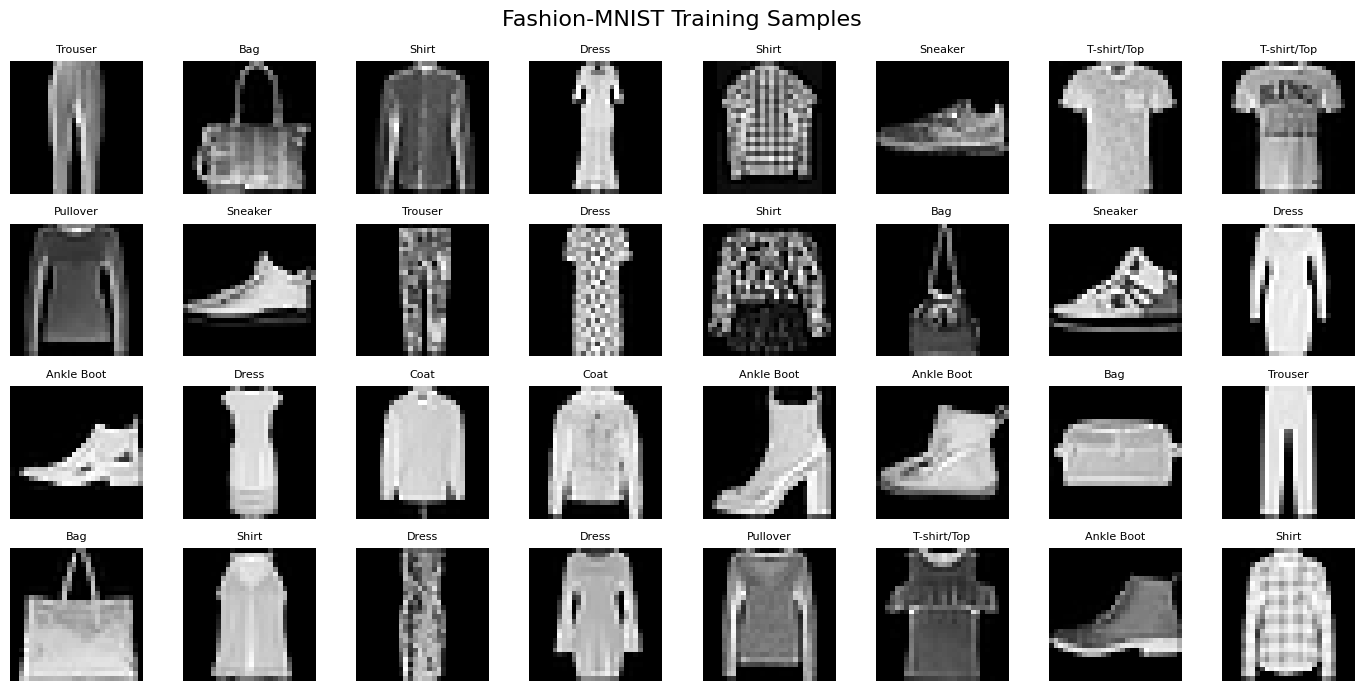

In [6]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(4, 8, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(class_names[labels[i].item()], fontsize=8)
    ax.axis("off")

plt.suptitle("Fashion-MNIST Training Samples", fontsize=16)
plt.tight_layout()
plt.show()


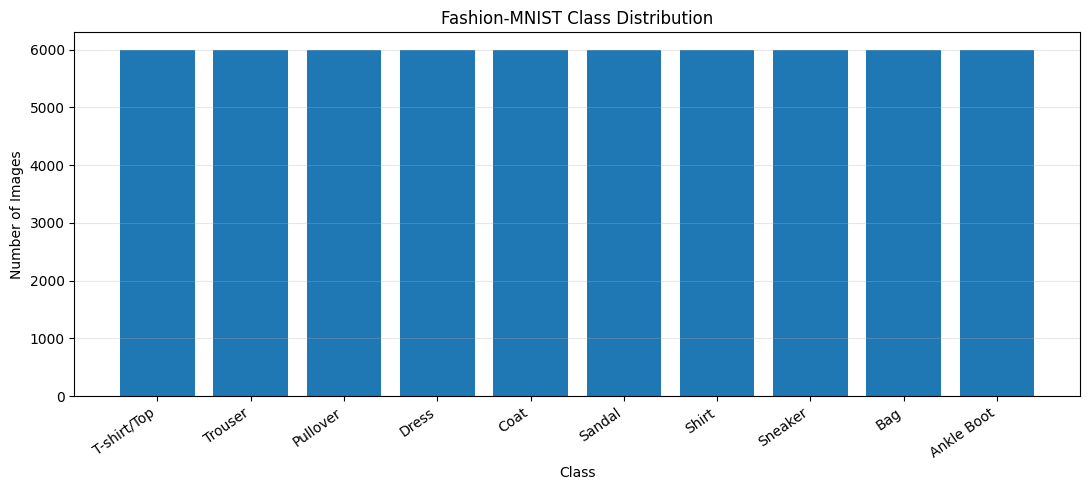

T-shirt/Top: 6000
Trouser: 6000
Pullover: 6000
Dress: 6000
Coat: 6000
Sandal: 6000
Shirt: 6000
Sneaker: 6000
Bag: 6000
Ankle Boot: 6000


In [7]:
from collections import Counter

label_counts = Counter(train_dataset.targets.tolist())

plt.figure(figsize=(11, 5))

plt.bar(
    [class_names[i] for i in range(10)],
    [label_counts[i] for i in range(10)]
)

plt.title("Fashion-MNIST Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

for i in range(10):
    print(f"{class_names[i]}: {label_counts[i]}")


In [8]:
import torchvision.transforms as transforms
from torchvision.datasets import FashionMNIST
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

images, labels = next(iter(train_loader))

print("Shape:", images.shape)
print("Min:", images.min().item())
print("Max:", images.max().item())


Shape: torch.Size([128, 1, 28, 28])
Min: -1.0
Max: 1.0


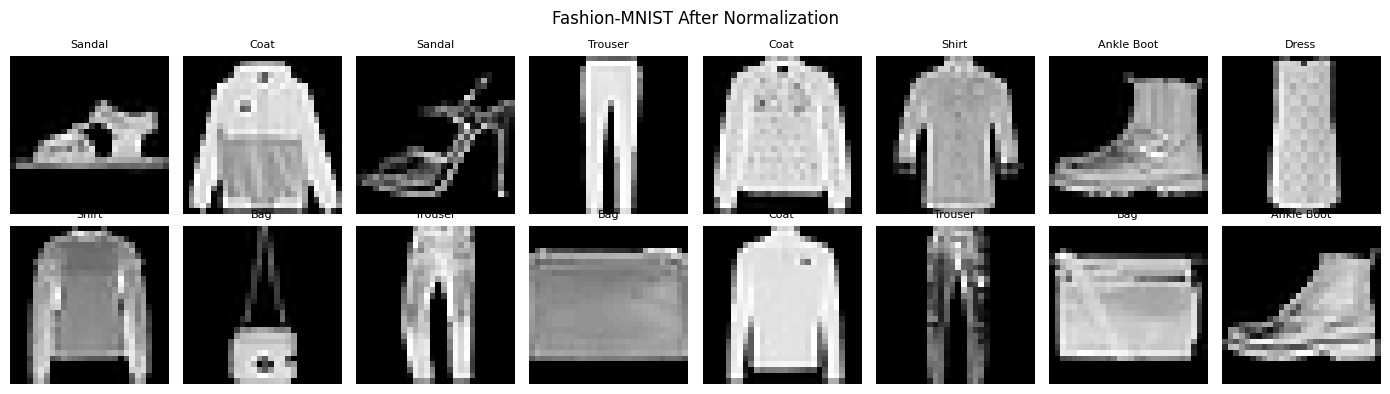

In [9]:

import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 8, figsize=(14, 4))

for i, ax in enumerate(axes.flat):
    image = images[i].squeeze().cpu()
    image = (image + 1) / 2

    ax.imshow(image, cmap="gray")
    ax.set_title(class_names[labels[i].item()], fontsize=8)
    ax.axis("off")

plt.suptitle("Fashion-MNIST After Normalization")
plt.tight_layout()
plt.show()


In [10]:
import torch

# DDPM hyperparameters
T = 1000

beta_start = 0.0001
beta_end = 0.02

# Linear noise schedule
betas = torch.linspace(
    beta_start,
    beta_end,
    T,
    device=device
)

# Alpha values
alphas = 1.0 - betas

# Cumulative product of alphas
alpha_bars = torch.cumprod(alphas, dim=0)

print("Number of timesteps:", T)
print("First beta:", betas[0].item())
print("Last beta:", betas[-1].item())
print("First alpha_bar:", alpha_bars[0].item())
print("Last alpha_bar:", alpha_bars[-1].item())


Number of timesteps: 1000
First beta: 9.999999747378752e-05
Last beta: 0.019999999552965164
First alpha_bar: 0.9998999834060669
Last alpha_bar: 4.035829260828905e-05


In [11]:

def q_sample(x_start, t, noise=None):
    """
    Generate noisy images at timestep t.

    x_start: Original images [B, C, H, W]
    t: Timesteps [B]
    noise: Gaussian noise with the same shape as x_start
    """

    if noise is None:
        noise = torch.randn_like(x_start)

    sqrt_alpha_bar = torch.sqrt(alpha_bars[t])
    sqrt_one_minus_alpha_bar = torch.sqrt(
        1.0 - alpha_bars[t]
    )

    # Reshape for broadcasting
    sqrt_alpha_bar = sqrt_alpha_bar.view(-1, 1, 1, 1)
    sqrt_one_minus_alpha_bar = sqrt_one_minus_alpha_bar.view(
        -1, 1, 1, 1
    )

    # Forward diffusion equation
    x_t = (
        sqrt_alpha_bar * x_start
        + sqrt_one_minus_alpha_bar * noise
    )

    return x_t


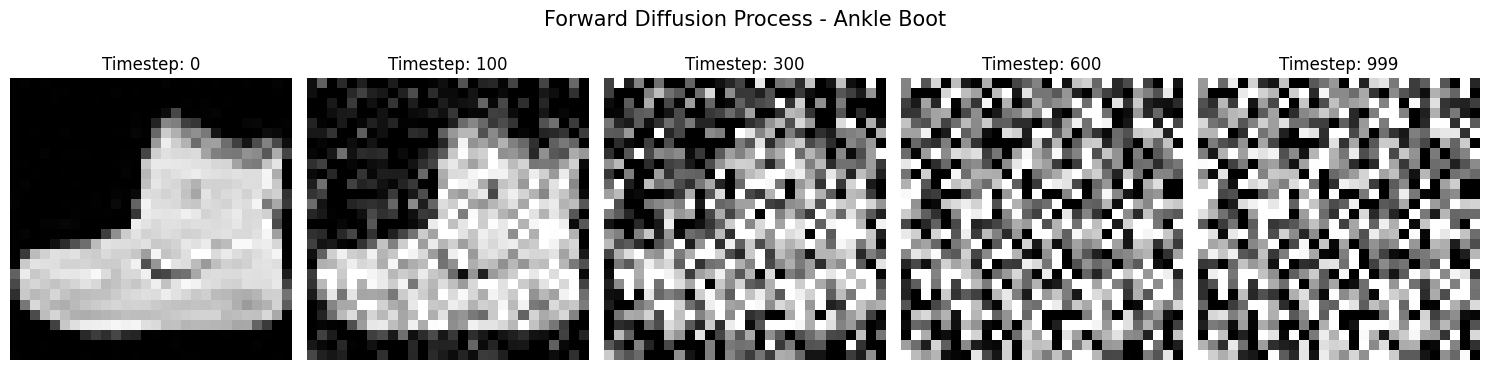

In [12]:

import matplotlib.pyplot as plt

# Select one original image
x_start, label = train_dataset[0]

x_start = x_start.unsqueeze(0).to(device)

# Timesteps for visualization
timesteps = [0, 100, 300, 600, 999]

# Use the same Gaussian noise for all timesteps
noise = torch.randn_like(x_start)

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, t_value in enumerate(timesteps):

    t = torch.tensor([t_value], device=device)

    # Generate noisy image
    x_t = q_sample(x_start, t, noise)

    # Convert to display range [0, 1]
    display_image = (
        x_t.squeeze().detach().cpu() + 1
    ) / 2

    display_image = display_image.clamp(0, 1)

    axes[i].imshow(display_image, cmap="gray")
    axes[i].set_title(f"Timestep: {t_value}")
    axes[i].axis("off")

plt.suptitle(
    f"Forward Diffusion Process - {class_names[label]}",
    fontsize=15
)

plt.tight_layout()
plt.show()


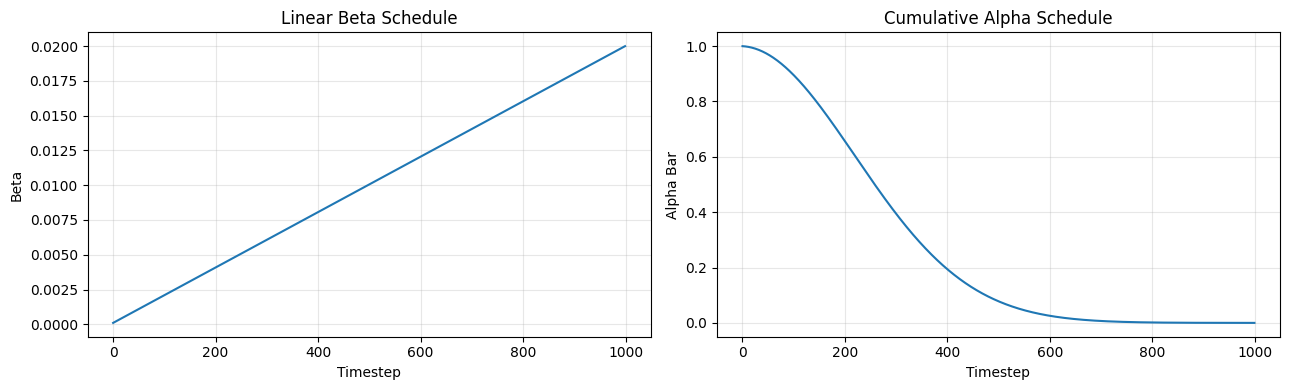

In [13]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Beta schedule
axes[0].plot(
    betas.detach().cpu().numpy()
)
axes[0].set_title("Linear Beta Schedule")
axes[0].set_xlabel("Timestep")
axes[0].set_ylabel("Beta")
axes[0].grid(alpha=0.3)

# Cumulative alpha
axes[1].plot(
    alpha_bars.detach().cpu().numpy()
)
axes[1].set_title("Cumulative Alpha Schedule")
axes[1].set_xlabel("Timestep")
axes[1].set_ylabel("Alpha Bar")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [14]:

import math
import torch
import torch.nn as nn
import torch.nn.functional as F

def sinusoidal_embedding(timesteps, dim):
    """
    Convert timestep indices into sinusoidal embeddings.
    timesteps: [B]
    output: [B, dim]
    """

    half_dim = dim // 2

    frequencies = torch.exp(
        -math.log(10000)
        * torch.arange(
            half_dim,
            device=timesteps.device,
            dtype=torch.float32
        ) / half_dim
    )

    angles = timesteps.float().unsqueeze(1) * frequencies.unsqueeze(0)

    embedding = torch.cat(
        [torch.sin(angles), torch.cos(angles)],
        dim=1
    )

    if dim % 2 == 1:
        embedding = F.pad(embedding, (0, 1))

    return embedding


In [15]:

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, padding=1
        )

        self.time_proj = nn.Linear(time_dim, out_channels)

        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, padding=1
        )

        self.shortcut = (
            nn.Conv2d(in_channels, out_channels, 1)
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x, t_emb):

        h = self.norm1(x)
        h = F.silu(h)
        h = self.conv1(h)

        time_embedding = self.time_proj(t_emb)
        h = h + time_embedding[:, :, None, None]

        h = self.norm2(h)
        h = F.silu(h)
        h = self.conv2(h)

        return h + self.shortcut(x)


In [16]:

class UNet(nn.Module):
    def __init__(self, in_channels=1, time_dim=256):
        super().__init__()

        self.time_dim = time_dim

        # Time embedding network
        self.time_mlp = nn.Sequential(
            nn.Linear(time_dim, time_dim * 4),
            nn.SiLU(),
            nn.Linear(time_dim * 4, time_dim)
        )

        # Initial convolution
        self.conv_in = nn.Conv2d(
            in_channels, 64,
            kernel_size=3, padding=1
        )

        # Encoder
        self.enc1 = ResidualBlock(64, 64, time_dim)
        self.down1 = nn.Conv2d(
            64, 128, 4, stride=2, padding=1
        )

        self.enc2 = ResidualBlock(128, 128, time_dim)
        self.down2 = nn.Conv2d(
            128, 256, 4, stride=2, padding=1
        )

        # Bottleneck
        self.mid1 = ResidualBlock(256, 256, time_dim)
        self.mid2 = ResidualBlock(256, 256, time_dim)

        # Decoder
        self.up2 = nn.ConvTranspose2d(
            256, 128, 4, stride=2, padding=1
        )
        self.dec2 = ResidualBlock(256, 128, time_dim)

        self.up1 = nn.ConvTranspose2d(
            128, 64, 4, stride=2, padding=1
        )
        self.dec1 = ResidualBlock(128, 64, time_dim)

        # Output layer
        self.output = nn.Sequential(
            nn.GroupNorm(8, 64),
            nn.SiLU(),
            nn.Conv2d(64, in_channels, 3, padding=1)
        )

    def forward(self, x, t):

        # Time embedding
        t_emb = sinusoidal_embedding(t, self.time_dim)
        t_emb = self.time_mlp(t_emb)

        # Encoder
        x = self.conv_in(x)

        skip1 = self.enc1(x, t_emb)
        x = self.down1(skip1)

        skip2 = self.enc2(x, t_emb)
        x = self.down2(skip2)

        # Bottleneck
        x = self.mid1(x, t_emb)
        x = self.mid2(x, t_emb)

        # Decoder with skip connections
        x = self.up2(x)
        x = torch.cat([x, skip2], dim=1)
        x = self.dec2(x, t_emb)

        x = self.up1(x)
        x = torch.cat([x, skip1], dim=1)
        x = self.dec1(x, t_emb)

        return self.output(x)


In [17]:

model = UNet(
    in_channels=1,
    time_dim=256
).to(device)

total_params = sum(
    p.numel() for p in model.parameters()
)

print(model)
print("\nTotal parameters:", f"{total_params:,}")


UNet(
  (time_mlp): Sequential(
    (0): Linear(in_features=256, out_features=1024, bias=True)
    (1): SiLU()
    (2): Linear(in_features=1024, out_features=256, bias=True)
  )
  (conv_in): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (enc1): ResidualBlock(
    (norm1): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (time_proj): Linear(in_features=256, out_features=64, bias=True)
    (norm2): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (shortcut): Identity()
  )
  (down1): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (enc2): ResidualBlock(
    (norm1): GroupNorm(8, 128, eps=1e-05, affine=True, bias=True)
    (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (time_proj): Linear(in_features=256, out_features=128, bias=True)
    (norm2)

In [18]:

# Get one batch
images, labels = next(iter(train_loader))
images = images.to(device)

# Generate random timesteps
batch_size = images.shape[0]

t = torch.randint(
    0, T,
    (batch_size,),
    device=device
)

# Generate noisy images
noise = torch.randn_like(images)
x_t = q_sample(images, t, noise)

# Predict noise
model.eval()

with torch.no_grad():
    predicted_noise = model(x_t, t)

print("Original images:", images.shape)
print("Noisy images:", x_t.shape)
print("Predicted noise:", predicted_noise.shape)

print(
    "Output shape matches:",
    predicted_noise.shape == noise.shape
)


Original images: torch.Size([128, 1, 28, 28])
Noisy images: torch.Size([128, 1, 28, 28])
Predicted noise: torch.Size([128, 1, 28, 28])
Output shape matches: True


In [19]:

def ddpm_loss(model, x_start):
    """
    DDPM simplified training objective.

    x_start: Original images [B, C, H, W]
    """

    batch_size = x_start.shape[0]

    # 1. Sample random timesteps
    t = torch.randint(
        0,
        T,
        (batch_size,),
        device=x_start.device
    )

    # 2. Sample Gaussian noise
    noise = torch.randn_like(x_start)

    # 3. Generate noisy images
    x_t = q_sample(x_start, t, noise)

    # 4. Predict noise using U-Net
    predicted_noise = model(x_t, t)

    # 5. Calculate MSE loss
    loss = F.mse_loss(predicted_noise, noise)

    return loss


In [20]:

LEARNING_RATE = 2e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

# Test one training step
model.train()

images, labels = next(iter(train_loader))
images = images.to(device)

optimizer.zero_grad()

loss = ddpm_loss(model, images)

loss.backward()
optimizer.step()

print("Initial training loss:", loss.item())


Initial training loss: 1.1057994365692139


In [21]:

# Cumulative alpha at previous timestep
alpha_bars_prev = torch.cat([
    torch.ones(1, device=device),
    alpha_bars[:-1]
])

# Posterior variance
posterior_variance = (
    betas * (1.0 - alpha_bars_prev)
    / (1.0 - alpha_bars)
)

print("Posterior variance shape:", posterior_variance.shape)
print("First variance:", posterior_variance[0].item())
print("Last variance:", posterior_variance[-1].item())


Posterior variance shape: torch.Size([1000])
First variance: 0.0
Last variance: 0.01999998278915882


In [22]:

@torch.no_grad()
def p_sample(model, x, t):
    """
    Perform one reverse diffusion step.

    x: Current noisy image
    t: Current timestep
    """

    # Predict Gaussian noise
    predicted_noise = model(x, t)

    # Extract coefficients for current timestep
    beta_t = betas[t].view(-1, 1, 1, 1)
    alpha_t = alphas[t].view(-1, 1, 1, 1)
    alpha_bar_t = alpha_bars[t].view(-1, 1, 1, 1)

    # Reverse process mean
    mean = (
        1.0 / torch.sqrt(alpha_t)
    ) * (
        x - (
            beta_t / torch.sqrt(1.0 - alpha_bar_t)
        ) * predicted_noise
    )

    # Posterior variance
    variance = posterior_variance[t].view(-1, 1, 1, 1)

    # No additional noise at the final step
    if t[0].item() == 0:
        return mean

    noise = torch.randn_like(x)

    return mean + torch.sqrt(variance) * noise


In [23]:

@torch.no_grad()
def sample_images(model, num_images=16, return_trajectory=False):
    """
    Generate new images using DDPM reverse sampling.
    """

    model.eval()

    # Start from random Gaussian noise
    x = torch.randn(
        num_images, 1, 28, 28,
        device=device
    )

    trajectory = []

    # Reverse diffusion: T-1 -> 0
    for step in reversed(range(T)):

        t = torch.full(
            (num_images,),
            step,
            device=device,
            dtype=torch.long
        )

        x = p_sample(model, x, t)

        # Save selected intermediate steps
        if return_trajectory and step in [999, 750, 500, 250, 100, 0]:
            trajectory.append((step, x[0].detach().cpu().clone()))

    if return_trajectory:
        return x, trajectory

    return x


In [24]:

generated_images, trajectory = sample_images(
    model,
    num_images=4,
    return_trajectory=True
)

print("Generated images shape:", generated_images.shape)
print("Trajectory steps:", [step for step, _ in trajectory])


Generated images shape: torch.Size([4, 1, 28, 28])
Trajectory steps: [999, 750, 500, 250, 100, 0]


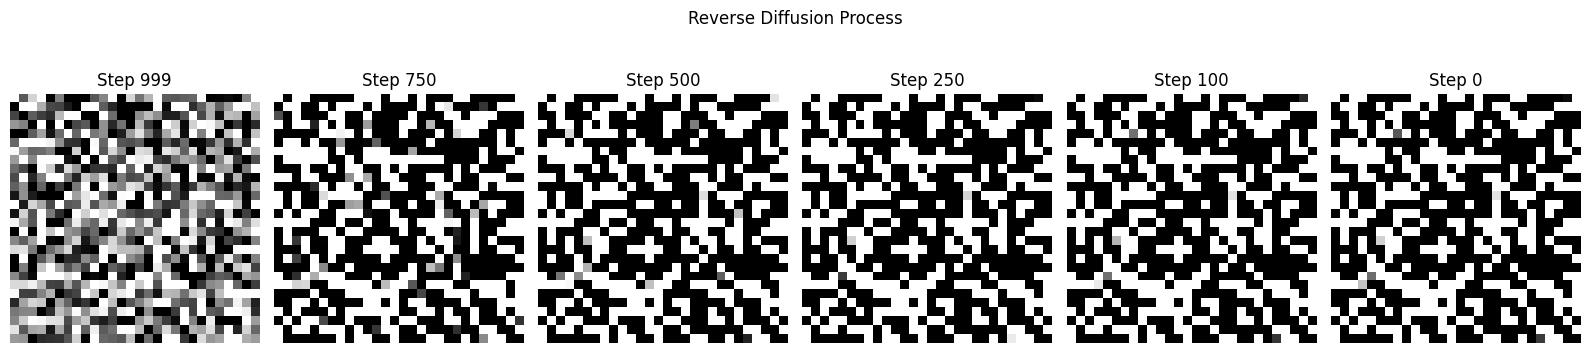

In [25]:

fig, axes = plt.subplots(1, len(trajectory), figsize=(16, 4))

for i, (step, image) in enumerate(trajectory):

    display_image = ((image.squeeze() + 1) / 2).clamp(0, 1)

    axes[i].imshow(display_image, cmap="gray")
    axes[i].set_title(f"Step {step}")
    axes[i].axis("off")

plt.suptitle("Reverse Diffusion Process")
plt.tight_layout()
plt.show()


In [26]:

from tqdm.auto import tqdm
import torch.nn.functional as F

EPOCHS = 20
LEARNING_RATE = 2e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

def train_one_epoch(model, dataloader, optimizer):
    model.train()
    total_loss = 0.0

    progress_bar = tqdm(dataloader, desc="Training")

    for images, _ in progress_bar:
        images = images.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        loss = ddpm_loss(model, images)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return total_loss / len(dataloader)


@torch.no_grad()
def validate(model, dataloader, max_batches=50):
    model.eval()
    total_loss = 0.0
    num_batches = min(len(dataloader), max_batches)

    for batch_idx, (images, _) in enumerate(dataloader):
        if batch_idx >= num_batches:
            break

        images = images.to(device, non_blocking=True)
        loss = ddpm_loss(model, images)

        total_loss += loss.item()

    return total_loss / num_batches


In [27]:

train_losses = []
val_losses = []

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer
    )

    val_loss = validate(
        model,
        test_loader
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Train Loss: {train_loss:.6f}")
    print(f"Validation Loss: {val_loss:.6f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "val_loss": val_loss
        }, "best_ddpm_fashion_mnist.pth")

        print("Best model checkpoint saved!")



Epoch 1/20


Training:   0%|          | 0/468 [00:00<?, ?it/s]

Train Loss: 0.083325
Validation Loss: 0.059026
Best model checkpoint saved!

Epoch 2/20


Training:   0%|          | 0/468 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f46e2964900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f46e2964900>

AssertionError: Traceback (most recent call last):
can only test a child process
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Train Loss: 0.052250
Validation Loss: 0.048950
Best model checkpoint saved!

Epoch 3/20


... (50 outputs left out)

Train Loss: 0.037470
Validation Loss: 0.038642

Epoch 20/20


Training:   0%|          | 0/468 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f46e2964900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    Exception ignored in: if w.is_alive():<function _MultiProcessingDataLoaderIter.__del__ at 0x7f46e2964900>

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Traceback (most recent call last):
    assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    
self._shutdown_workers()AssertionError: 
can only test a child process  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

    if w.is_alive():
  File "/usr/lib/

Train Loss: 0.037289
Validation Loss: 0.036886


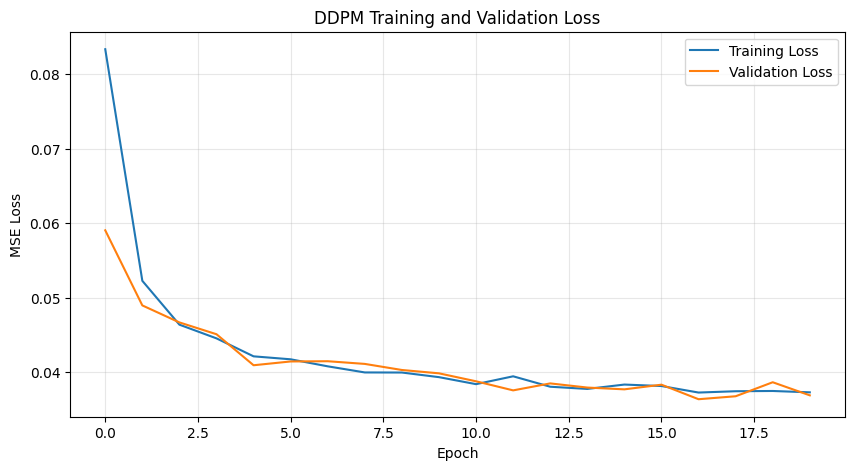

In [28]:

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("DDPM Training and Validation Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [29]:

checkpoint = torch.load(
    "best_ddpm_fashion_mnist.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Best checkpoint loaded successfully!")
print("Best Epoch:", checkpoint["epoch"])
print("Validation Loss:", checkpoint["val_loss"])


Best checkpoint loaded successfully!
Best Epoch: 17
Validation Loss: 0.03636476114392281


In [30]:

generated_images = sample_images(
    model,
    num_images=16
)

print("Generated images shape:", generated_images.shape)


Generated images shape: torch.Size([16, 1, 28, 28])


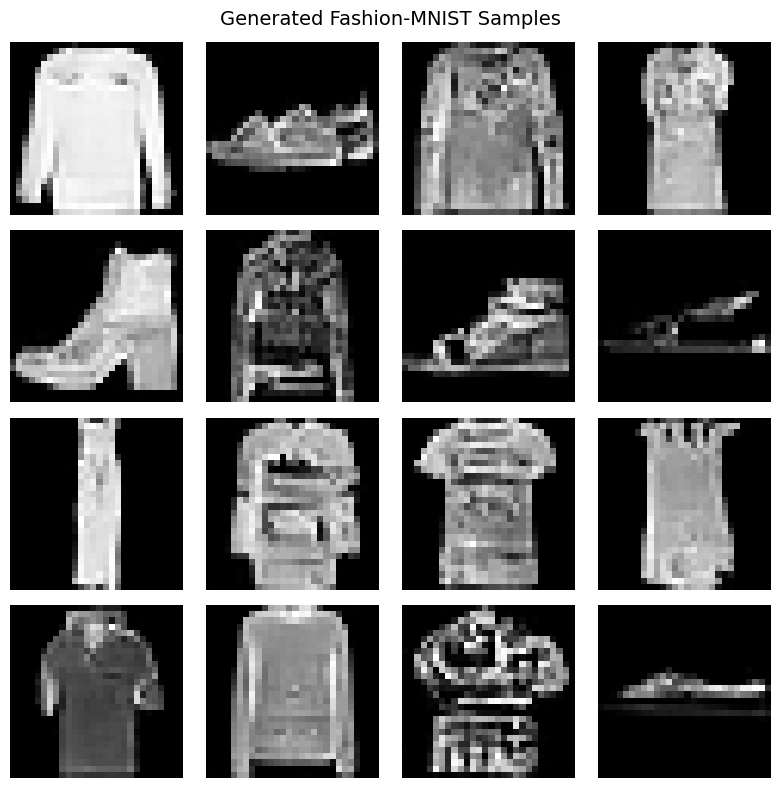

In [31]:

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    image = generated_images[i].squeeze().cpu()
    image = ((image + 1) / 2).clamp(0, 1)

    ax.imshow(image, cmap="gray")
    ax.axis("off")

plt.suptitle("Generated Fashion-MNIST Samples", fontsize=14)
plt.tight_layout()
plt.show()


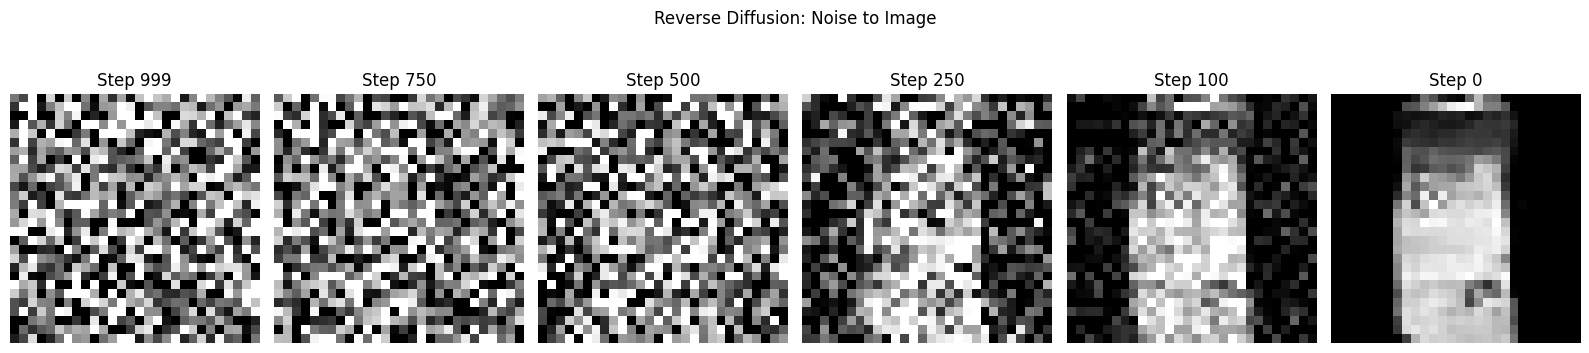

In [32]:

generated_images, trajectory = sample_images(
    model,
    num_images=4,
    return_trajectory=True
)

fig, axes = plt.subplots(
    1, len(trajectory),
    figsize=(16, 4)
)

for i, (step, image) in enumerate(trajectory):
    image = ((image.squeeze() + 1) / 2).clamp(0, 1)

    axes[i].imshow(image, cmap="gray")
    axes[i].set_title(f"Step {step}")
    axes[i].axis("off")

plt.suptitle("Reverse Diffusion: Noise to Image")
plt.tight_layout()
plt.show()


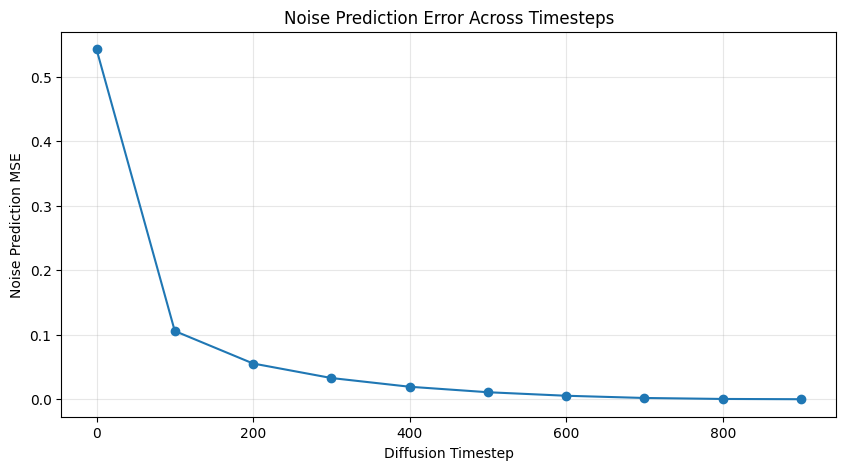

In [33]:

@torch.no_grad()
def evaluate_noise_by_timestep(
    model,
    dataloader,
    timesteps=None,
    max_batches=50
):
    model.eval()

    if timesteps is None:
        timesteps = list(range(0, T, 100))

    timestep_losses = []

    for step in timesteps:
        total_loss = 0.0
        count = 0

        for batch_idx, (images, _) in enumerate(dataloader):
            if batch_idx >= max_batches:
                break

            images = images.to(device)
            t = torch.full(
                (images.size(0),),
                step,
                device=device,
                dtype=torch.long
            )

            noise = torch.randn_like(images)
            noisy_images = q_sample(images, t, noise)

            predicted_noise = model(noisy_images, t)

            loss = F.mse_loss(predicted_noise, noise)

            total_loss += loss.item()
            count += 1

        timestep_losses.append(total_loss / count)

    return timestep_losses, timesteps


timestep_losses, evaluated_steps = evaluate_noise_by_timestep(
    model,
    test_loader
)

plt.figure(figsize=(10, 5))

plt.plot(
    evaluated_steps,
    timestep_losses,
    marker="o"
)

plt.xlabel("Diffusion Timestep")
plt.ylabel("Noise Prediction MSE")
plt.title("Noise Prediction Error Across Timesteps")
plt.grid(alpha=0.3)
plt.show()


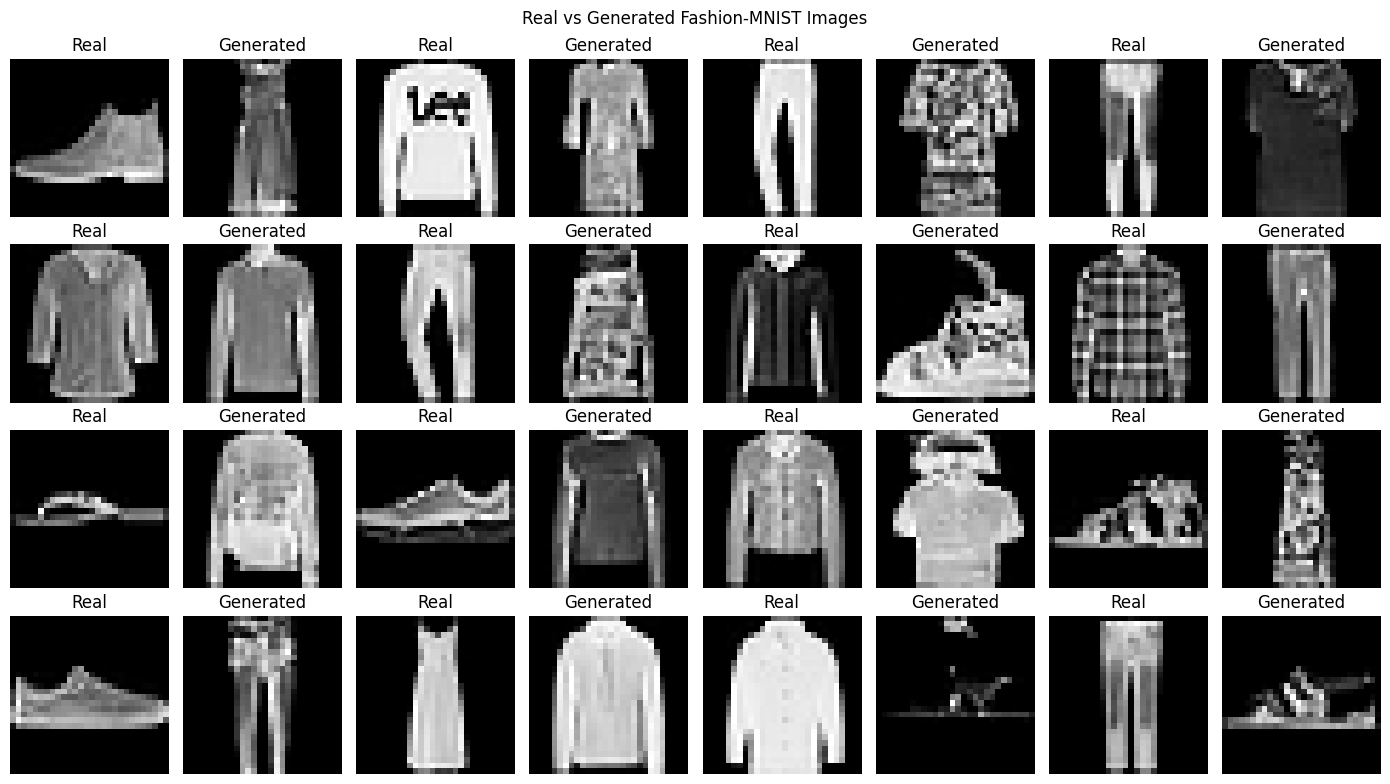

In [34]:

real_images, _ = next(iter(test_loader))

generated_images = sample_images(
    model,
    num_images=16
)

fig, axes = plt.subplots(4, 8, figsize=(14, 8))

for i in range(16):
    real = ((real_images[i].squeeze() + 1) / 2).clamp(0, 1)
    generated = ((generated_images[i].squeeze().cpu() + 1) / 2).clamp(0, 1)

    axes[i // 4, (i % 4) * 2].imshow(real, cmap="gray")
    axes[i // 4, (i % 4) * 2].set_title("Real")
    axes[i // 4, (i % 4) * 2].axis("off")

    axes[i // 4, (i % 4) * 2 + 1].imshow(generated, cmap="gray")
    axes[i // 4, (i % 4) * 2 + 1].set_title("Generated")
    axes[i // 4, (i % 4) * 2 + 1].axis("off")

plt.suptitle("Real vs Generated Fashion-MNIST Images")
plt.tight_layout()
plt.show()


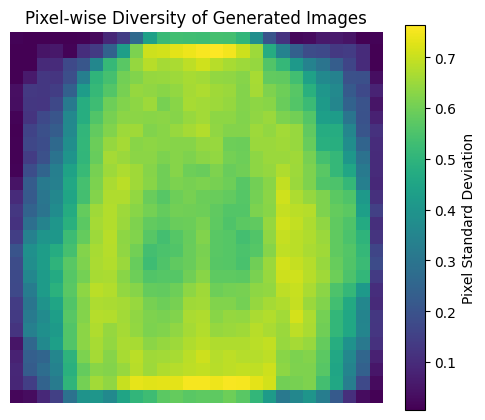

Mean pixel standard deviation: 0.49622151255607605


In [35]:

generated_images = sample_images(
    model,
    num_images=256
)

generated = generated_images.detach().cpu()

pixel_std = generated.std(dim=0).squeeze(0)

plt.figure(figsize=(6, 5))
plt.imshow(pixel_std, cmap="viridis")
plt.colorbar(label="Pixel Standard Deviation")
plt.title("Pixel-wise Diversity of Generated Images")
plt.axis("off")
plt.show()

print("Mean pixel standard deviation:", pixel_std.mean().item())
